# Amine BOURAMTANE

# TP — Amélioration de la qualité d’image : filtrage

Objectif : charger et analyser une image, réduire le bruit, corriger les couleurs ou la luminosité, accentuer les détails et comparer les résultats. Les sections suivent les sept étapes de l’énoncé.

Deux expériences sont distinguées :
- **Photo locale telle quelle** : observations visuelles, sans prétendre connaître une version parfaite.
- **Dégradations contrôlées de cette photo** : bruit et dominante colorée ajoutés avec une graine fixe ; la photo avant dégradation sert alors de référence pour les mesures.



In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('resultats_filtrage')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'font.size':10})
print('Interpréteur :', sys.executable)
print('OpenCV :', cv2.__version__)

def u8(image):
    return np.clip(np.rint(image),0,255).astype(np.uint8)

def gray(image):
    return cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

def save_rgb(name,image):
    if not cv2.imwrite(str(OUT/name),cv2.cvtColor(image,cv2.COLOR_RGB2BGR)):
        raise OSError(f'Échec de sauvegarde : {name}')

def show_images(items,title,filename=None):
    n=len(items)
    fig,axes=plt.subplots(1,n,figsize=(4*n,4.5),squeeze=False)
    for ax,(label,image) in zip(axes.ravel(),items):
        ax.imshow(image,cmap='gray' if image.ndim==2 else None,vmin=0,vmax=255)
        ax.set_title(label); ax.axis('off')
    fig.suptitle(title)
    fig.tight_layout()
    if filename: fig.savefig(OUT/filename,bbox_inches='tight',dpi=140)
    plt.show()


Interpréteur : /home/amine/anaconda3/envs/myenv/bin/python
OpenCV : 4.13.0


## 1 — Chargement d’une image

Les images sont lues avec OpenCV puis converties de BGR vers RGB pour l’affichage. Nous utilisons la photographie couleur fournie dans `./images_color.jpeg` pour toutes les étapes, y compris la correction des couleurs. Modifier `IMAGE_PATH` permet de travailler sur une autre photo.

Le côté maximal est limité à 640 pixels en conservant les proportions. Cette taille est utilisée pour toutes les méthodes, ce qui rend leur comparaison cohérente.

Image choisie : images_color.jpeg
Dimensions : (640, 427, 3) ; type : uint8


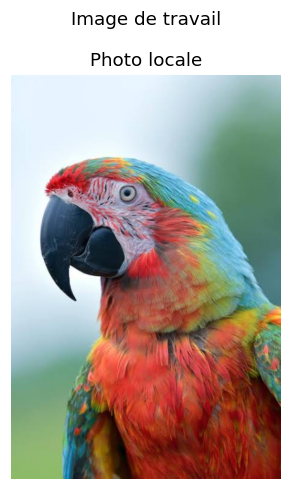

In [ ]:
IMAGE_PATH = Path('images_color.jpeg')
if not IMAGE_PATH.is_file():
    raise FileNotFoundError('Placer images_color.jpeg à côté du notebook ou adapter IMAGE_PATH.')
bgr=cv2.imread(str(IMAGE_PATH),cv2.IMREAD_COLOR)
if bgr is None: raise ValueError(f'Image illisible : {IMAGE_PATH}')
reference=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
scale=min(1.,640/max(reference.shape[:2]))
if scale<1:
    reference=cv2.resize(reference,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA)
print('Image choisie :', IMAGE_PATH)
print('Dimensions :',reference.shape,'; type :',reference.dtype)
save_rgb('01_image_originale.png',reference)
show_images([('Photo locale',reference)],'Image de travail','01_originale.png')


## 2 — Analyse de l’image

Nous examinons la luminosité, la dynamique, l’écart entre canaux et les contours. Une photographie essentiellement grise ne permet pas de démontrer la récupération de couleurs absentes. Les moyennes R/V/B décrivent l’image, mais une différence entre elles ne prouve pas une mauvaise balance des blancs : elle peut être due à la scène.

La variance du Laplacien est un **indicateur de hautes fréquences**. Elle augmente avec les détails, mais aussi avec le bruit : ce n’est pas une mesure autonome de qualité et elle n’identifie pas avec certitude le bruit ou le flou.

,luminance_moyenne,ecart_type_gris,percentile_1,percentile_99,moyenne_R,moyenne_V,moyenne_B,ecart_canaux_moyen,variance_laplacien
Photo originale,141.127,65.645,21.0,250.0,151.502,138.183,128.949,64.362,270.449


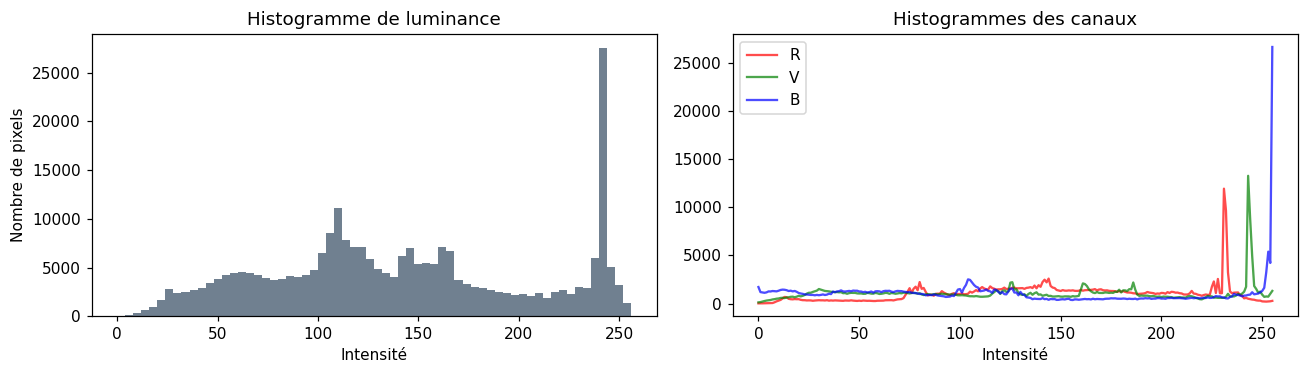

**Observation :** L’image présente des différences entre canaux, sans que cela prouve une dominante incorrecte. La luminance moyenne vaut 141.1/255 et les percentiles 1–99 vont de 21 à 250. Le bruit initial ne peut pas être mesuré exactement sans référence.

In [ ]:
def diagnostics(image):
    g=gray(image)
    return {'luminance_moyenne':float(g.mean()),'ecart_type_gris':float(g.std()),
            'percentile_1':float(np.percentile(g,1)),'percentile_99':float(np.percentile(g,99)),
            'moyenne_R':float(image[:,:,0].mean()),'moyenne_V':float(image[:,:,1].mean()),
            'moyenne_B':float(image[:,:,2].mean()),
            'ecart_canaux_moyen':float(np.ptp(image.astype(float),axis=2).mean()),
            'variance_laplacien':float(cv2.Laplacian(g,cv2.CV_32F).var())}

diag=diagnostics(reference)
display(pd.DataFrame([diag],index=['Photo originale']).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
axes[0].hist(gray(reference).ravel(),bins=64,range=(0,256),color='slategray')
axes[0].set(title='Histogramme de luminance',xlabel='Intensité',ylabel='Nombre de pixels')
for channel,color,label in zip(range(3),['red','green','blue'],['R','V','B']):
    hist=cv2.calcHist([reference],[channel],None,[256],[0,256]).ravel()
    axes[1].plot(hist,color=color,label=label,alpha=.7)
axes[1].set(title='Histogrammes des canaux',xlabel='Intensité'); axes[1].legend()
plt.tight_layout(); fig.savefig(OUT/'02_histogrammes.png',bbox_inches='tight'); plt.show()
color_note = ('L’image est essentiellement en niveaux de gris.' if diag['ecart_canaux_moyen']<5
              else 'L’image présente des différences entre canaux, sans que cela prouve une dominante incorrecte.')
display(Markdown(f'**Observation :** {color_note} La luminance moyenne vaut {diag["luminance_moyenne"]:.1f}/255 et les percentiles 1–99 vont de {diag["percentile_1"]:.0f} à {diag["percentile_99"]:.0f}. Le bruit initial ne peut pas être mesuré exactement sans référence.'))


## 3 — Réduction du bruit

Un filtre **gaussien 5 × 5, σ = 1** moyenne les pixels voisins en pondérant leur distance ; il réduit les fluctuations, mais adoucit les contours. Le **filtre médian 3 × 3** remplace chaque pixel par la médiane locale ; il est particulièrement adapté au bruit impulsionnel « sel et poivre ».

Pour vérifier ces comportements, nous ajoutons séparément :
- un bruit gaussien de σ = 15 niveaux d’intensité ;
- un bruit sel et poivre touchant environ 4 % des pixels, les trois canaux étant affectés ensemble.

Les réalisations de bruit sont identiques pour les méthodes comparées. La MSE et la PSNR utilisent la photo avant ajout du bruit comme référence. Une PSNR plus élevée indique une meilleure fidélité pixel à pixel, sans suffire à définir la qualité perceptuelle.

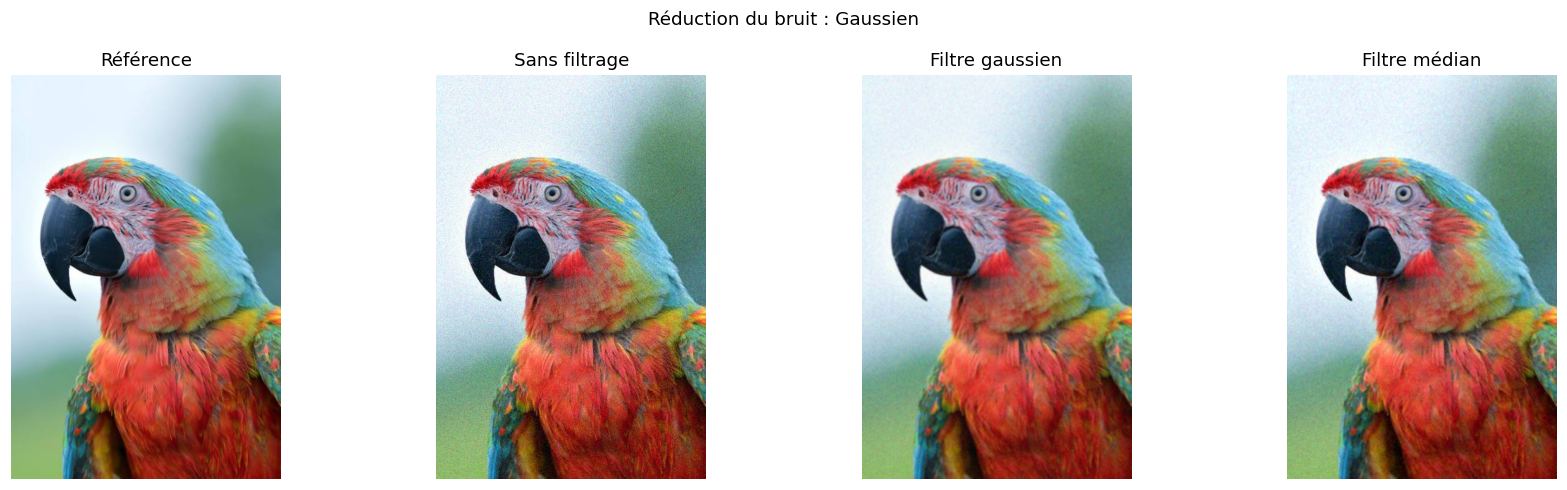

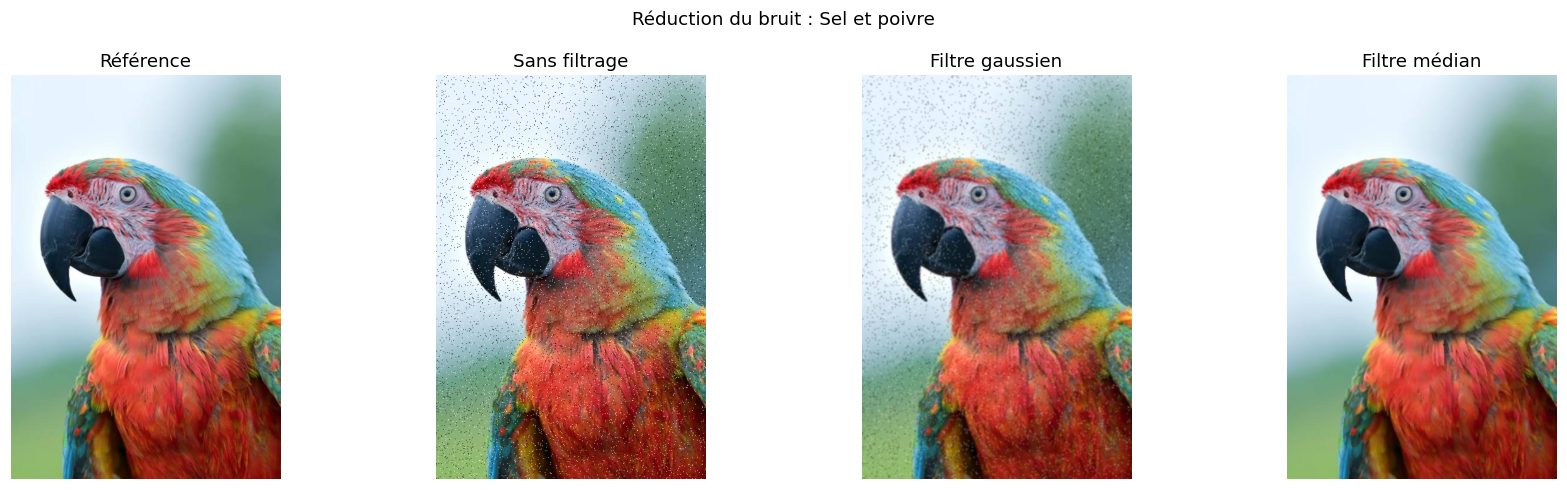

,bruit,méthode,MSE,PSNR_dB
0,Gaussien,Sans filtrage,207.290,24.965
1,Gaussien,Filtre gaussien,42.830,31.813
2,Gaussien,Filtre médian,55.783,30.666
3,Sel et poivre,Sans filtrage,878.462,18.694
4,Sel et poivre,Filtre gaussien,106.893,27.841
5,Sel et poivre,Filtre médian,16.930,35.844


**Résultat (Gaussien) :** Filtre gaussien donne la PSNR la plus élevée parmi les configurations comparées : **31.81 dB**. Ce classement dépend du bruit, de l’image et des tailles de noyaux.

**Résultat (Sel et poivre) :** Filtre médian donne la PSNR la plus élevée parmi les configurations comparées : **35.84 dB**. Ce classement dépend du bruit, de l’image et des tailles de noyaux.

In [ ]:
def gaussian_noise(image,sigma=15):
    return u8(image.astype(float)+rng.normal(0,sigma,image.shape))

def salt_pepper(image,amount=.04):
    corrupted=image.copy()
    sample=rng.random(image.shape[:2])
    corrupted[sample<amount/2]=0
    corrupted[(sample>=amount/2)&(sample<amount)]=255
    return corrupted

def gaussian_filter(image):
    return cv2.GaussianBlur(image,(5,5),sigmaX=1.0,borderType=cv2.BORDER_REFLECT_101)

def median_filter(image):
    return cv2.medianBlur(image,3)

def fidelity(ref,image):
    mse=float(np.mean((ref.astype(float)-image.astype(float))**2))
    return {'MSE':mse,'PSNR_dB':float(10*np.log10(255**2/mse)) if mse else np.inf}

noise_images={'Gaussien':gaussian_noise(reference),'Sel et poivre':salt_pepper(reference)}
noise_results={}
rows=[]
for noise_name,noisy in noise_images.items():
    results={'Sans filtrage':noisy,'Filtre gaussien':gaussian_filter(noisy),'Filtre médian':median_filter(noisy)}
    noise_results[noise_name]=results
    for name,image in results.items():
        rows.append({'bruit':noise_name,'méthode':name,**fidelity(reference,image)})
    slug='gaussien' if noise_name=='Gaussien' else 'sel_poivre'
    show_images([('Référence',reference),*results.items()],f'Réduction du bruit : {noise_name}',f'03_bruit_{slug}.png')
noise_metrics=pd.DataFrame(rows)
display(noise_metrics.round(3))
noise_metrics.to_csv(OUT/'comparaison_debruitage.csv',index=False)
for noise_name,group in noise_metrics.groupby('bruit'):
    best=group.loc[group.PSNR_dB.idxmax()]
    display(Markdown(f'**Résultat ({noise_name}) :** {best["méthode"]} donne la PSNR la plus élevée parmi les configurations comparées : **{best["PSNR_dB"]:.2f} dB**. Ce classement dépend du bruit, de l’image et des tailles de noyaux.'))


## 4 — Correction des couleurs et de la luminosité

### Balance des blancs : hypothèse du monde gris

On suppose que la moyenne des trois canaux devrait être neutre. Chaque canal est multiplié par le rapport entre la moyenne globale et sa moyenne propre. Cette hypothèse peut échouer si une couleur domine naturellement la scène ; des gains extrêmes sont limités et l’écrêtage peut perdre de l’information.

Nous appliquons la balance des blancs à une version de l’image couleur dont le canal bleu a été artificiellement atténué. Cette dominante contrôlée permet une comparaison avec la photo avant modification. Le monde gris peut toutefois altérer les couleurs naturelles si la scène ne vérifie pas son hypothèse de neutralité.

### Correction gamma

Nous utilisons explicitement la convention $I_{sortie}=255(I_{entrée}/255)^\gamma$ : **γ < 1 éclaircit**, γ > 1 assombrit. C’est une correction tonale, pas une balance des blancs. Elle ne reconstruit pas les détails perdus dans les zones saturées.

Gains monde gris [R,V,B] : [0.762 0.983 1.492]


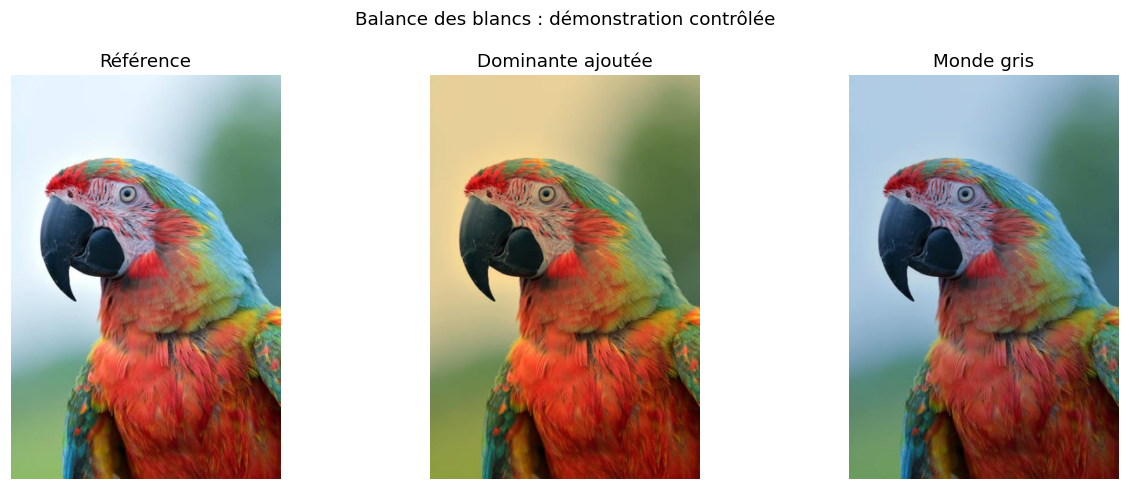

,méthode,MSE,PSNR_dB
0,Dominante ajoutée,1452.131,16.511
1,Monde gris,813.187,19.029


**Interprétation :** le monde gris équilibre les moyennes des canaux, mais ne restaure pas nécessairement la luminosité initiale : les gains de dégradation étaient inconnus de la méthode.

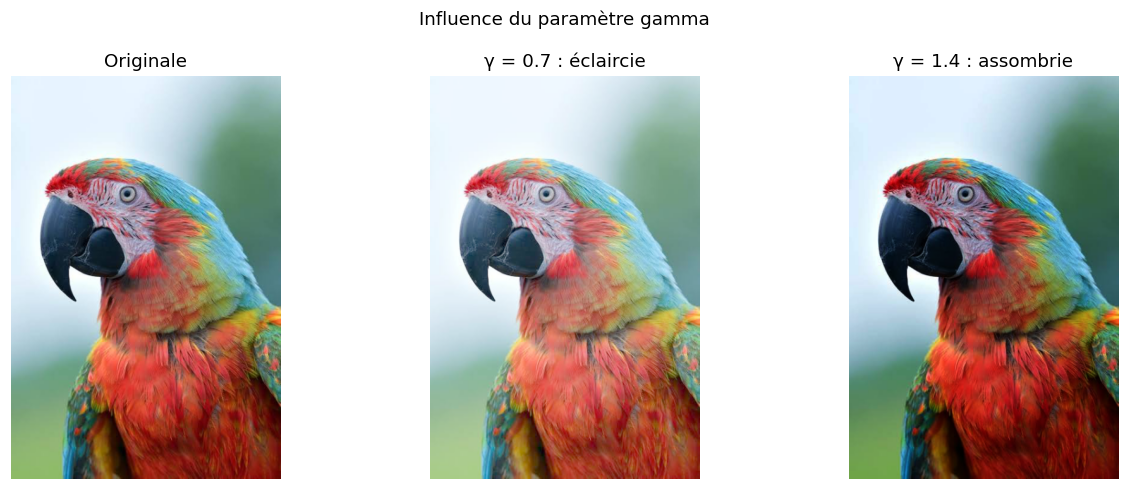

In [ ]:
def gray_world(image):
    values=image.astype(np.float32)
    means=values.mean(axis=(0,1))
    gains=np.clip(means.mean()/np.maximum(means,1e-6),0.5,2.0)
    return u8(values*gains),gains

def gamma_correct(image,gamma=0.8):
    if gamma<=0: raise ValueError('gamma doit être strictement positif')
    table=u8(255*(np.arange(256,dtype=float)/255)**gamma)
    return cv2.LUT(image,table)

cast_gains=np.array([1.0,.85,.60],dtype=np.float32)
tinted=u8(reference.astype(float)*cast_gains)
wb,gains=gray_world(tinted)
show_images([('Référence',reference),('Dominante ajoutée',tinted),('Monde gris',wb)],
            'Balance des blancs : démonstration contrôlée','04_balance_blancs.png')
print('Gains monde gris [R,V,B] :',np.round(gains,3))
display(pd.DataFrame([{'méthode':name,**fidelity(reference,im)} for name,im in [('Dominante ajoutée',tinted),('Monde gris',wb)]]).round(3))
display(Markdown('**Interprétation :** le monde gris équilibre les moyennes des canaux, mais ne restaure pas nécessairement la luminosité initiale : les gains de dégradation étaient inconnus de la méthode.'))
show_images([('Originale',reference),('γ = 0.7 : éclaircie',gamma_correct(reference,.7)),
             ('γ = 1.4 : assombrie',gamma_correct(reference,1.4))],
            'Influence du paramètre gamma','04_gamma.png')


## 5 — Accentuation des détails avec le Laplacien

Le Laplacien mesure des variations rapides d’intensité. Avec le signe utilisé par OpenCV, nous appliquons :

$$I_{accentuée}=\operatorname{clip}(I-\alpha\,\Delta I,0,255),\qquad \alpha=0.15.$$

Le calcul se fait en flottants pour conserver les dérivées négatives. Nous renforçons seulement la luminance dans l’espace LAB afin de limiter les modifications de teinte. Un lissage préalable est nécessaire lorsque l’image est bruitée. Une accentuation excessive peut créer des halos, écrêter des valeurs et amplifier le bruit ; elle ne recrée pas les détails qui ont disparu.

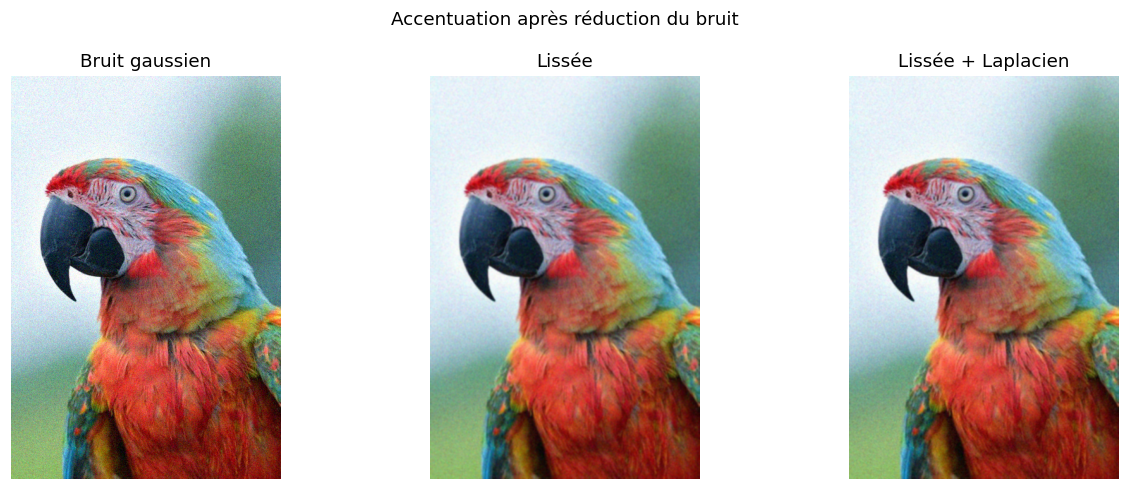

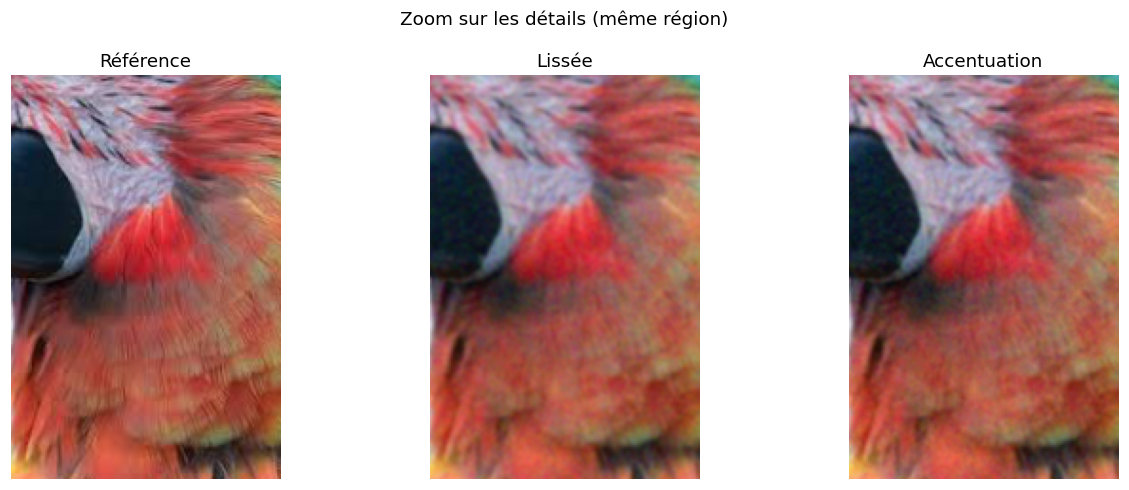

,étape,MSE,PSNR_dB,variance_laplacien
0,Bruitée,207.290,24.965,2147.748
1,Lissée,42.830,31.813,35.945
2,Accentuation,40.216,32.087,66.325


**Lecture :** une hausse de variance du Laplacien signifie davantage de hautes fréquences. Vérifier le zoom pour distinguer contours utiles, bruit et halos. La PSNR peut baisser après accentuation, même si les contours paraissent plus marqués.

In [ ]:
def laplacian_sharpen(image,alpha=.15):
    lab=cv2.cvtColor(image,cv2.COLOR_RGB2LAB)
    luminance=lab[:,:,0].astype(np.float32)
    lap=cv2.Laplacian(luminance,cv2.CV_32F,ksize=1,borderType=cv2.BORDER_REFLECT_101)
    lab[:,:,0]=u8(luminance-alpha*lap)
    return cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)

noisy=noise_images['Gaussien']
denoised=gaussian_filter(noisy)
sharpened=laplacian_sharpen(denoised)
show_images([('Bruit gaussien',noisy),('Lissée',denoised),('Lissée + Laplacien',sharpened)],
            'Accentuation après réduction du bruit','05_accentuation.png')
# Zoom central identique pour observer les contours.
h,w=reference.shape[:2]
y0,y1=h//3,2*h//3
x0,x1=w//3,2*w//3
show_images([(name,im[y0:y1,x0:x1]) for name,im in [('Référence',reference),('Lissée',denoised),('Accentuation',sharpened)]],
            'Zoom sur les détails (même région)','05_zoom.png')
sharp_metrics=pd.DataFrame([{'étape':name,**fidelity(reference,im),
                             'variance_laplacien':diagnostics(im)['variance_laplacien']}
                            for name,im in [('Bruitée',noisy),('Lissée',denoised),('Accentuation',sharpened)]])
display(sharp_metrics.round(3))
sharp_metrics.to_csv(OUT/'comparaison_accentuation.csv',index=False)
display(Markdown('**Lecture :** une hausse de variance du Laplacien signifie davantage de hautes fréquences. Vérifier le zoom pour distinguer contours utiles, bruit et halos. La PSNR peut baisser après accentuation, même si les contours paraissent plus marqués.'))


## 6 — Chaîne complète et rapport court

### A. Traitement de la photo locale sans dégradation ajoutée

Nous utilisons un lissage modéré (gaussien 3 × 3, σ = 0.6), puis une correction gamma légère (γ = 0.9), puis une accentuation faible (α = 0.10). Ces paramètres illustrent une chaîne et ne sont pas automatiquement optimaux. La balance des blancs est montrée séparément : elle peut modifier les couleurs naturelles et aucune dominante incorrecte de la photographie fournie n’est établie.

L’image finale est une proposition de rendu. Sans référence propre de la scène, une différence avec l’original ne prouve pas une amélioration objective.

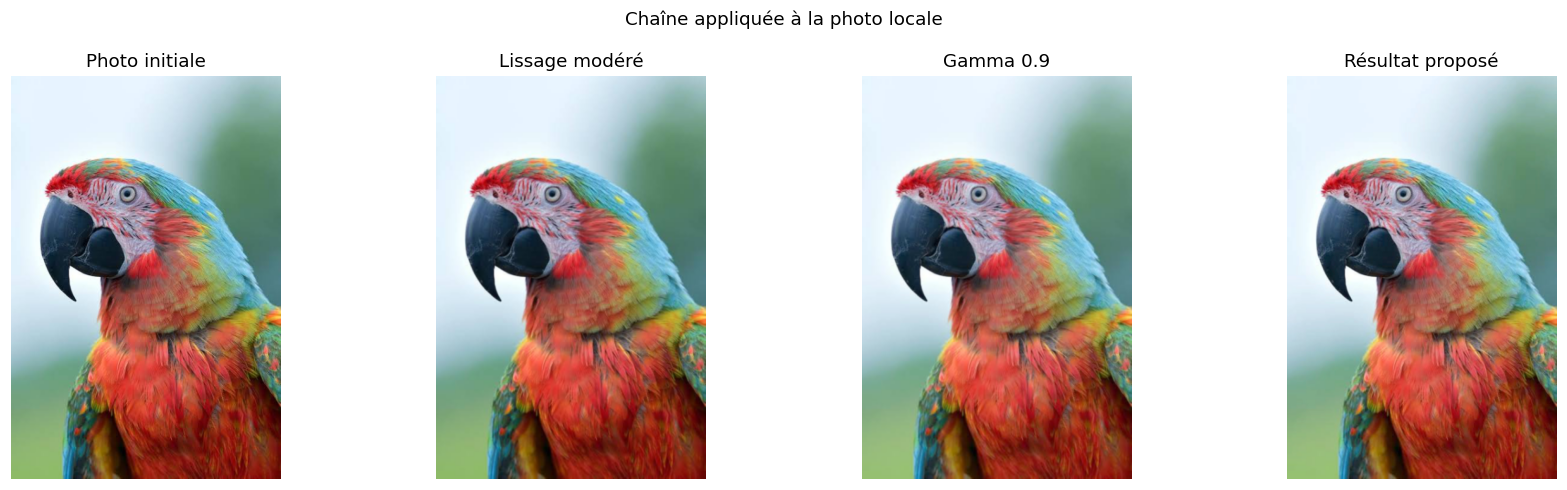

,étape,luminance_moyenne,ecart_type_gris,percentile_1,percentile_99,moyenne_R,moyenne_V,moyenne_B,ecart_canaux_moyen,variance_laplacien
0,Originale,141.127,65.645,21.0,250.0,151.502,138.183,128.949,64.362,270.449
1,Lissage,141.127,65.369,22.0,250.0,151.502,138.183,128.949,64.279,81.940
2,Gamma,147.674,63.170,28.0,250.0,158.327,144.698,135.062,63.068,79.669
3,Finale,147.823,63.342,27.0,250.0,158.387,144.845,135.144,63.126,124.764


In [ ]:
local_smooth=cv2.GaussianBlur(reference,(3,3),sigmaX=.6)
local_gamma=gamma_correct(local_smooth,.9)
local_final=laplacian_sharpen(local_gamma,.10)
show_images([('Photo initiale',reference),('Lissage modéré',local_smooth),
             ('Gamma 0.9',local_gamma),('Résultat proposé',local_final)],
            'Chaîne appliquée à la photo locale','06_chaine_locale.png')
local_stats=pd.DataFrame([{'étape':name,**diagnostics(im)} for name,im in
                          [('Originale',reference),('Lissage',local_smooth),('Gamma',local_gamma),('Finale',local_final)]])
display(local_stats.round(3))
local_stats.to_csv(OUT/'diagnostics_chaine_locale.csv',index=False)
save_rgb('06_resultat_photo_locale.png',local_final)


### B. Chaîne sur une dégradation contrôlée combinée

Nous ajoutons une dominante et du bruit gaussien, puis appliquons : gaussien → monde gris → gamma 0.85 → Laplacien. Les paramètres sont fixés à l’avance. La PSNR à chaque étape permet de constater qu’un traitement supplémentaire n’est pas nécessairement bénéfique. Le gamma corrige ici le rendu tonal de manière heuristique ; ce n’est pas l’inverse exact de la dégradation.

,étape,MSE,PSNR_dB
0,Dégradée,1591.289,16.113
1,Débruitage,1491.258,16.395
2,Balance blancs,857.336,18.799
3,Gamma,456.866,21.533
4,Laplacien,448.953,21.609


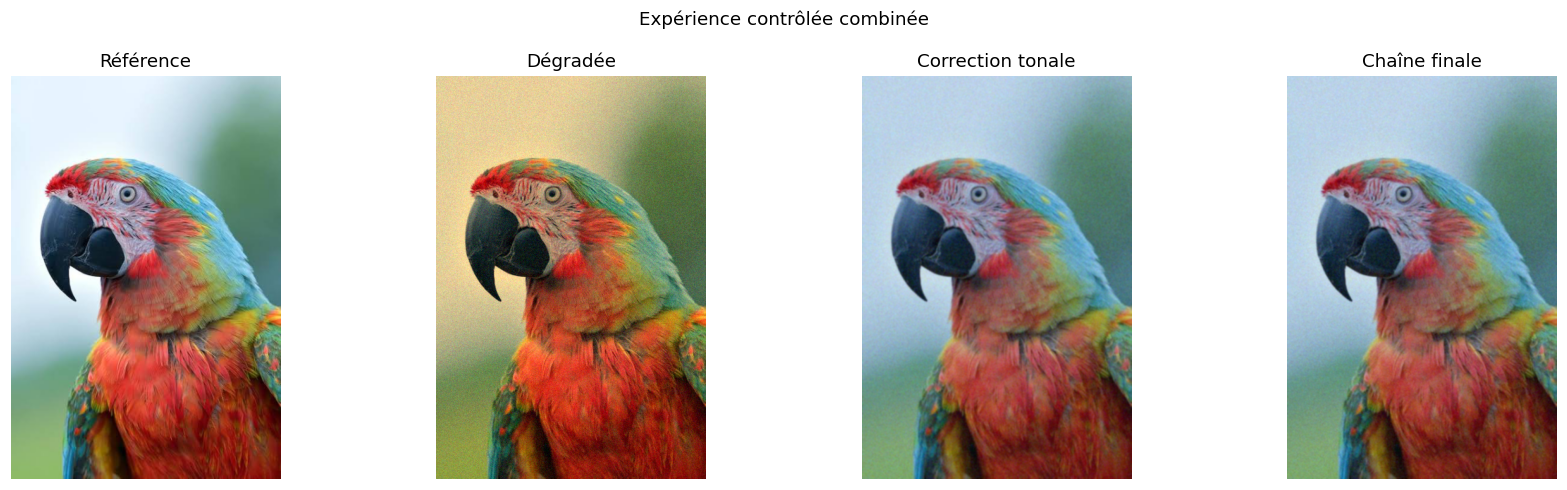

### 6. Rapport court — démarche, techniques, résultats et qualité

**Démarche.** Nous avons étudié une image couleur et ses histogrammes pour examiner la luminosité et la répartition des canaux. La photo `images_color.jpeg` a été chargée, analysée puis traitée. Le bruit ajouté est connu ; les défauts initiaux de la photographie restent inconnus.

**Techniques.** Nous avons comparé un filtre gaussien 5 × 5 (σ = 1) et un médian 3 × 3 sur deux dégradations distinctes : bruit gaussien (σ = 15) et bruit sel et poivre (4 %). La correction des couleurs repose sur le monde gris, qui équilibre les moyennes des canaux. La correction gamma ajuste la luminosité. Le Laplacien appliqué à la luminance LAB renforce les détails après lissage. La chaîne combinée utilise un bruit gaussien de σ = 12, puis le lissage, le monde gris, γ = 0.85 et une accentuation α = 0.15.

**Résultats.** Dans l’expérience combinée, la PSNR passe de **16.11 dB** à **21.61 dB** après la chaîne complète. Parmi les étapes testées, **Laplacien** obtient la meilleure PSNR (**21.61 dB**). Pour le bruit gaussien seul, le filtre gaussien donne **31.81 dB**, contre **30.67 dB** pour le médian. Pour le bruit sel et poivre, le médian atteint **35.84 dB**, contre **27.84 dB** pour le gaussien. Ces résultats comparent les réglages retenus sur cette image.

**Évaluation.** Les planches et le zoom permettent d’examiner le compromis bruit/détails. Les traitements peuvent lisser des textures, modifier la luminosité et produire des halos. Une hausse du contraste ou des hautes fréquences ne suffit pas à prouver une amélioration. Le résultat local sans bruit ajouté doit être jugé visuellement en fonction de l’usage souhaité. La PSNR est calculée uniquement lorsque la photo avant dégradation est disponible ; elle mesure la fidélité pixel à pixel, sans garantir un meilleur rendu perceptuel.

**Conclusion.** Le gaussien est adapté ici au bruit gaussien, tandis que le médian est particulièrement efficace contre les impulsions. La correction des couleurs et l’accentuation doivent rester modérées. Ces observations portent sur une photo et des dégradations contrôlées ; elles ne suffisent pas à conclure à une amélioration universelle.


In [ ]:
combined=gaussian_noise(tinted,sigma=12)
step_denoise=gaussian_filter(combined)
step_white,combined_gains=gray_world(step_denoise)
step_gamma=gamma_correct(step_white,.85)
step_final=laplacian_sharpen(step_gamma,.15)
steps={'Dégradée':combined,'Débruitage':step_denoise,'Balance blancs':step_white,
       'Gamma':step_gamma,'Laplacien':step_final}
full_metrics=pd.DataFrame([{'étape':name,**fidelity(reference,im)} for name,im in steps.items()])
display(full_metrics.round(3))
full_metrics.to_csv(OUT/'evaluation_chaine_controlee.csv',index=False)
show_images([('Référence',reference),('Dégradée',combined),('Correction tonale',step_gamma),('Chaîne finale',step_final)],
            'Expérience contrôlée combinée','06_chaine_controlee.png')
save_rgb('06_degradation_controlee.png',combined)
save_rgb('06_resultat_controle.png',step_final)
initial_psnr=full_metrics.iloc[0]['PSNR_dB']
final_psnr=full_metrics.iloc[-1]['PSNR_dB']
best=full_metrics.loc[full_metrics.PSNR_dB.idxmax()]
display(Markdown(f"""### 6. Rapport court — démarche, techniques, résultats et qualité

**Démarche.** Nous avons étudié une image couleur et ses histogrammes pour examiner la luminosité et la répartition des canaux. La photo `{IMAGE_PATH.name}` a été chargée, analysée puis traitée. Le bruit ajouté est connu ; les défauts initiaux de la photographie restent inconnus.

**Techniques.** Nous avons comparé un filtre gaussien 5 × 5 (σ = 1) et un médian 3 × 3 sur deux dégradations distinctes : bruit gaussien (σ = 15) et bruit sel et poivre (4 %). La correction des couleurs repose sur le monde gris, qui équilibre les moyennes des canaux. La correction gamma ajuste la luminosité. Le Laplacien appliqué à la luminance LAB renforce les détails après lissage. La chaîne combinée utilise un bruit gaussien de σ = 12, puis le lissage, le monde gris, γ = 0.85 et une accentuation α = 0.15.

**Résultats.** Dans l’expérience combinée, la PSNR passe de **{initial_psnr:.2f} dB** à **{final_psnr:.2f} dB** après la chaîne complète. Parmi les étapes testées, **{best['étape']}** obtient la meilleure PSNR (**{best['PSNR_dB']:.2f} dB**). Pour le bruit gaussien seul, le filtre gaussien donne **{noise_metrics.query("bruit == 'Gaussien' and méthode == 'Filtre gaussien'").iloc[0]['PSNR_dB']:.2f} dB**, contre **{noise_metrics.query("bruit == 'Gaussien' and méthode == 'Filtre médian'").iloc[0]['PSNR_dB']:.2f} dB** pour le médian. Pour le bruit sel et poivre, le médian atteint **{noise_metrics.query("bruit == 'Sel et poivre' and méthode == 'Filtre médian'").iloc[0]['PSNR_dB']:.2f} dB**, contre **{noise_metrics.query("bruit == 'Sel et poivre' and méthode == 'Filtre gaussien'").iloc[0]['PSNR_dB']:.2f} dB** pour le gaussien. Ces résultats comparent les réglages retenus sur cette image.

**Évaluation.** Les planches et le zoom permettent d’examiner le compromis bruit/détails. Les traitements peuvent lisser des textures, modifier la luminosité et produire des halos. Une hausse du contraste ou des hautes fréquences ne suffit pas à prouver une amélioration. Le résultat local sans bruit ajouté doit être jugé visuellement en fonction de l’usage souhaité. La PSNR est calculée uniquement lorsque la photo avant dégradation est disponible ; elle mesure la fidélité pixel à pixel, sans garantir un meilleur rendu perceptuel.

**Conclusion.** Le gaussien est adapté ici au bruit gaussien, tandis que le médian est particulièrement efficace contre les impulsions. La correction des couleurs et l’accentuation doivent rester modérées. Ces observations portent sur une photo et des dégradations contrôlées ; elles ne suffisent pas à conclure à une amélioration universelle.
"""))


## 7 — Discussion et comparaison

| Technique | Avantage | Inconvénient / effet sur la qualité |
|---|---|---|
| Gaussien | Réduction simple des fluctuations aléatoires | Adoucit contours et textures ; efficacité dépend de σ et du noyau |
| Médian | Efficace contre les impulsions sel et poivre | Peut supprimer de petites structures ; moins adapté à certaines textures |
| Monde gris | Balance des blancs simple, sans objet de calibration | Suppose une moyenne neutre ; peut dénaturer une scène colorée ; écrêtage possible |
| Gamma | Ajustement progressif de la luminosité | Amplifie parfois le bruit des ombres ; ne récupère pas les valeurs saturées |
| Laplacien | Renforcement visible des contours | Amplifie le bruit et peut créer des halos ; nécessite un dosage faible |

**Pourquoi l’ordre compte-t-il ?** Réduire le bruit avant d’accentuer évite de renforcer d’abord les fluctuations indésirables. La balance des blancs modifie les canaux tandis que le gamma change les niveaux ; ces opérations ne commutent pas en général. Chaque étape doit être utile au défaut observé.

**Comment choisir les paramètres ?** Commencer par de petits noyaux et de faibles gains, inspecter des régions contenant bords et textures, puis comparer plusieurs réglages. Un réglage choisi pour cette image ne constitue pas une méthode universelle ; une validation sur plusieurs scènes serait nécessaire.

**Quelles limites pour les mesures ?** La PSNR mesure la fidélité à la photo avant bruit ajouté, pas une qualité humaine absolue. Le bruit synthétique n’imite pas tous les défauts d’un capteur ou du JPEG. La variance du Laplacien confond netteté et bruit ; les histogrammes ne décrivent pas la structure spatiale.

**Conclusion.** Le prétraitement implique un compromis entre réduction du bruit, conservation des détails et rendu tonal. Les expériences contrôlées permettent une comparaison chiffrée ; le traitement de la photo d’origine reste une proposition visuelle. Une chaîne plus longue ne garantit pas un meilleur résultat.


In [ ]:
# Contrôles de cohérence et inventaire des livrables.
for name,image in {'référence':reference,**steps,'résultat local':local_final}.items():
    assert image.shape==reference.shape, name
    assert image.dtype==np.uint8, name
assert np.isfinite(noise_metrics[['MSE','PSNR_dB']].to_numpy()).all()
assert all(np.isfinite(full_metrics[['MSE','PSNR_dB']].to_numpy()).ravel())
print('Vérifications terminées. Résultats enregistrés dans :',OUT.resolve())
for path in sorted(OUT.iterdir()): print(' -',path.name)


Vérifications terminées. Résultats enregistrés dans : /home/amine/Desktop/vision-par-ordinateur/seance44/dataset/resultats_filtrage
 - 01_image_originale.png
 - 01_originale.png
 - 02_histogrammes.png
 - 03_bruit_gaussien.png
 - 03_bruit_sel_poivre.png
 - 04_balance_blancs.png
 - 04_gamma.png
 - 05_accentuation.png
 - 05_zoom.png
 - 06_chaine_controlee.png
 - 06_chaine_locale.png
 - 06_degradation_controlee.png
 - 06_resultat_controle.png
 - 06_resultat_photo_locale.png
 - comparaison_accentuation.csv
 - comparaison_debruitage.csv
 - diagnostics_chaine_locale.csv
 - evaluation_chaine_controlee.csv
